# Port Value Models

We have 3 models of how the rat learns each port's value (its expected reward probability) over a session. Here we fit each one to 2 example sessions (a probability change session and a barrier change session), see which one best explains the rat's choices, and look at the port values each one learns.

If you haven't yet, start with [Port Value Learning](40_Port_Value_Learning.ipynb), which shows the data each model needs (the port the rat ran to and whether it got rewarded, for every trial in order) and how to get port values per trial. For more (fitting to rewards, uncertainty, what each parameter does), see [Port Value Models Extended](42_Port_Value_Models_Extended.ipynb).

## The models

### Rescorla-Wagner (Q-learning)

Each port has a value $Q$ (starting at 0.5). After the rat runs to a port and gets reward $r$ (1 or 0), that port's value moves toward the outcome by the learning rate $\alpha$:

$$\delta = r - Q(\text{port}) \qquad\qquad Q(\text{port}) \leftarrow Q(\text{port}) + \alpha \, \delta$$

$\delta$ is the reward prediction error. Each trial, every port's value also decays back toward 0.5 (forgetting, or expecting the reward probabilities to change):

$$Q \leftarrow (1 - d) \, Q + d \cdot 0.5$$

**Parameters:** learning rate $\alpha$, decay $d$. Each port is learned on its own.

### Bayesian

Each port has a Beta$(a, b)$ belief about its reward probability, where $a$ counts rewards and $b$ counts omissions. The port's value is the mean of that belief:

$$\text{reward: } a \leftarrow a + 1 \qquad \text{no reward: } b \leftarrow b + 1 \qquad\qquad V(\text{port}) = \frac{a}{a + b}$$

Every port starts at Beta$(s, s)$ (value 0.5), where $s$ is the prior strength: a bigger $s$ means more visits are needed to move the value (like a lower learning rate). Each trial, every $a$ and $b$ decays back toward $s$: $a \leftarrow (1 - d) \, a + d \, s$ (and the same for $b$).

Unlike Rescorla-Wagner, each visit moves the value less as the counts grow, so the model learns fast about ports it knows little about and slowly about ports it knows well (unless decay keeps the counts small).

**Parameters:** prior strength $s$, decay $d$. Each port is learned on its own.

### Hidden State

Assumes the 3 ports have reward probabilities 0.9, 0.5 and 0.1, but the rat doesn't know which port has which. That gives 6 possible assignments (states), and the model keeps a belief $b(\text{state})$ over them. After reward $r$ at a port, it updates the belief with Bayes' rule:

$$b(\text{state}) \leftarrow \frac{b(\text{state}) \, P(r \mid \text{state}, \text{port})}{\sum_{\text{states}} b(\text{state}) \, P(r \mid \text{state}, \text{port})}$$

where $P(r = 1 \mid \text{state}, \text{port})$ is the reward probability that state gives the port. A port's value is its reward probability averaged over the states:

$$V(\text{port}) = \sum_{\text{states}} b(\text{state}) \, P(r = 1 \mid \text{state}, \text{port})$$

A learning rate $\alpha$ blends the updated belief with the old one ($\alpha = 1$ is the full Bayesian update), and each trial the belief decays toward uniform: $b \leftarrow (1 - d) \, b + d / 6$ (expecting the probabilities to change).

**Parameters:** learning rate $\alpha$, decay $d$. Unlike the other 2 models, the ports aren't learned on their own: a reward at A also says something about B and C (if A is the 0.9 port, B and C must be 0.5 and 0.1).

### How the rat chooses (all models)

On each trial the rat chooses between the 2 ports it didn't just leave, with a softmax over their values:

$$P(\text{port}) = \frac{e^{\beta \, V(\text{port})}}{\sum_{\text{available ports}} e^{\beta \, V}}$$

$\beta$ is the inverse temperature: higher $\beta$ means the rat more reliably chooses the higher valued port ($\beta = 0$ is random).

(There's also a `BayesianHiddenStatePortLearner`, still in progress, which learns the 3 reward probabilities too instead of assuming 0.9, 0.5 and 0.1.)

## Fit each model to the rat's choices

`fit_choices` fits each model's 2 parameters and $\beta$ (so 3 parameters each) to maximize the likelihood of the rat's choices. We fit all 3 models to each example session.

In [1]:
import sys
sys.path.append("..")  # Use sys to add the parent directory (where src/hexmaze lives) to the path

import matplotlib.pyplot as plt
import pandas as pd
from src.hexmaze.rl.port_learning import (
    RescorlaWagner, BayesianPortLearner, HiddenStatePortLearner, port_values_per_trial,
)
from tutorial_utils import draw_blocks, load_session

# Load the example sessions
probability_session = load_session("example_data/IM-1871_20250802_ep0_98178d7d.csv")
barrier_session = load_session("example_data/Toby20250327_ep7_b94510ec.csv")
print(f"Probability change session (rat IM-1871): {len(probability_session['ports'])} trials")
print(f"Barrier change session (rat Toby): {len(barrier_session['ports'])} trials")

# Fit each model's parameters (and beta, the inverse temperature) to the rat's choices in the probability change session
# (all we need is the port the rat ran to on each trial and whether it got rewarded)
probability_rw_fit = RescorlaWagner.fit_choices(probability_session["ports"], probability_session["rewards"])
probability_bayes_fit = BayesianPortLearner.fit_choices(probability_session["ports"], probability_session["rewards"])
probability_hidden_state_fit = HiddenStatePortLearner.fit_choices(probability_session["ports"], probability_session["rewards"])

# Same for the barrier change session
barrier_rw_fit = RescorlaWagner.fit_choices(barrier_session["ports"], barrier_session["rewards"])
barrier_bayes_fit = BayesianPortLearner.fit_choices(barrier_session["ports"], barrier_session["rewards"])
barrier_hidden_state_fit = HiddenStatePortLearner.fit_choices(barrier_session["ports"], barrier_session["rewards"])

# Put the sessions and fits in dicts so we can loop through them for the tables and plots below
sessions = {"Probability change (rat IM-1871)": probability_session, "Barrier change (rat Toby)": barrier_session}
fits = {
    "Probability change (rat IM-1871)": {
        "Rescorla-Wagner": probability_rw_fit, "Bayesian": probability_bayes_fit, "Hidden State": probability_hidden_state_fit,
    },
    "Barrier change (rat Toby)": {
        "Rescorla-Wagner": barrier_rw_fit, "Bayesian": barrier_bayes_fit, "Hidden State": barrier_hidden_state_fit,
    },
}

Probability change session (rat IM-1871): 178 trials
Barrier change session (rat Toby): 216 trials


## Which model fits best?

For each session and model: the fitted parameters, its choice NLL (negative log-likelihood of the rat's choices, lower is better) and its BIC. BIC $= k \ln(n) + 2 \cdot \text{NLL}$ (with $k$ parameters and $n$ trials) penalizes extra parameters, so models with different numbers of parameters can be compared. All 3 models here have 3 parameters, so comparing BIC is the same as comparing NLL. A BIC difference above about 10 is strong evidence for the model with the lower BIC.

In [2]:
# Each model's fitted parameters (prior_strength sets both prior_a and prior_b, so we show prior_a)
parameters = {
    "Rescorla-Wagner": lambda fit: f"alpha = {fit.alpha:.3f}, decay = {fit.decay:.3f}",
    "Bayesian": lambda fit: f"prior_strength = {fit.prior_a:.3f}, decay = {fit.decay:.3f}",
    "Hidden State": lambda fit: f"alpha = {fit.alpha:.3f}, decay = {fit.decay:.3f}",
}
# Loop through sessions to make a table of fit stats for each (1 row per model)
for session_name, session_fits in fits.items():
    comparison = pd.DataFrame({
        name: {
            "parameters": parameters[name](fit),
            "beta (inverse temp)": round(fit.beta, 3),
            "choice NLL": round(fit.choice_nll_, 1),
            "BIC": round(fit.choice_bic_, 1),
        }
        for name, fit in session_fits.items()
    }).T
    # Best model first
    print(session_name)
    display(comparison.sort_values("BIC"))

Probability change (rat IM-1871)


,parameters,beta (inverse temp),choice NLL,BIC
Bayesian,"prior_strength = 0.686, decay = 0.003",5.231,72.3,160.1
Hidden State,"alpha = 1.000, decay = 0.000",3.232,77.0,169.4
Rescorla-Wagner,"alpha = 0.067, decay = 0.000",6.537,81.0,177.6


Barrier change (rat Toby)


,parameters,beta (inverse temp),choice NLL,BIC
Bayesian,"prior_strength = 0.000, decay = 0.115",5.662,39.3,94.7
Rescorla-Wagner,"alpha = 0.342, decay = 0.000",6.462,41.9,99.9
Hidden State,"alpha = 0.868, decay = 0.008",6.628,43.0,102.1


## Port values from each model

For each session, each model's port values at the start of every trial (the values the rat chose with), with a dot on the trials the rat ran to that port (filled if rewarded). The red lines are where each new block starts (where the reward probabilities or the barriers changed), with the reward probabilities written above the plot whenever they change.

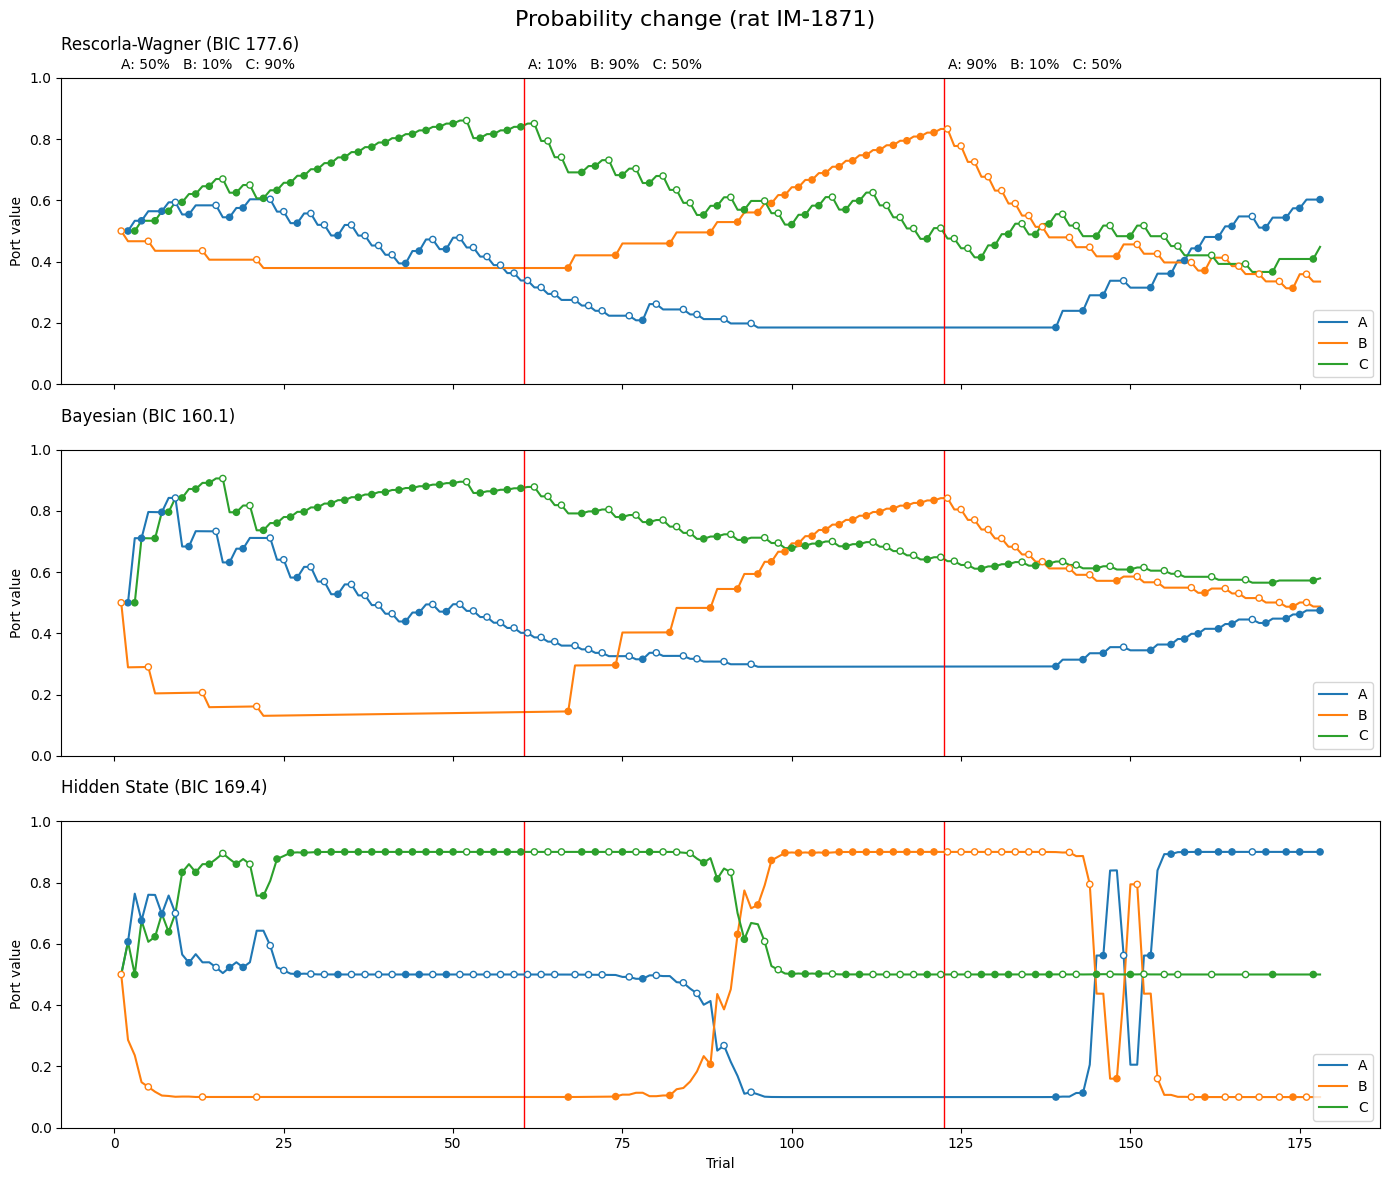

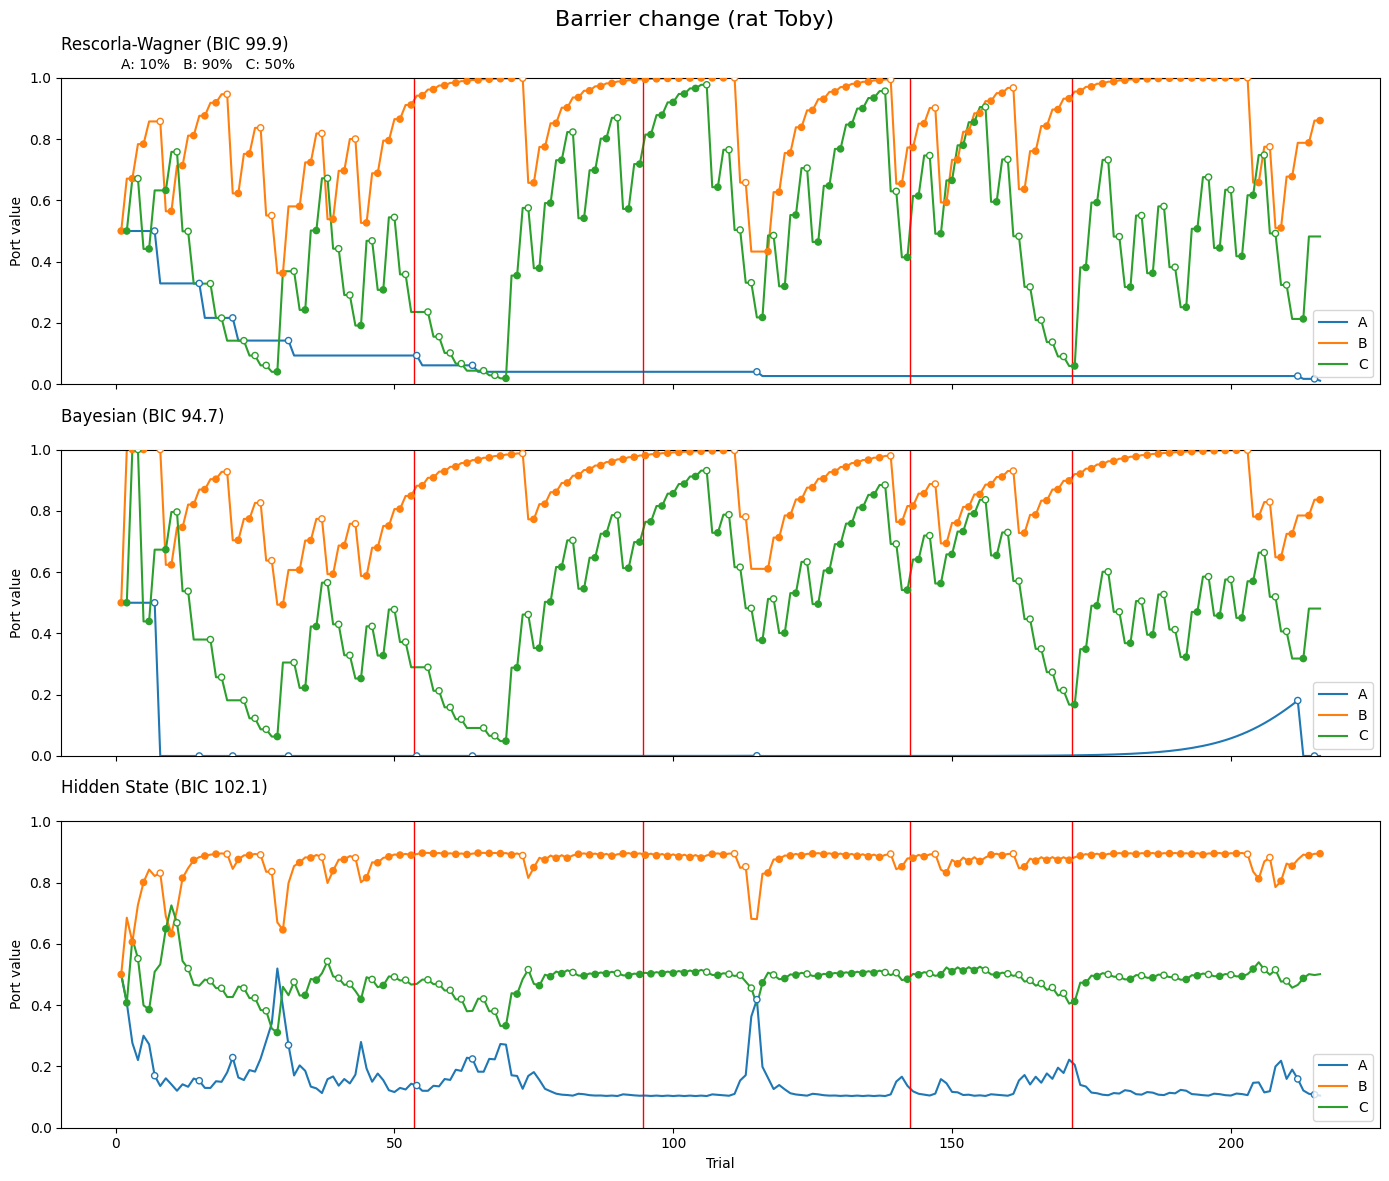

In [3]:
PORT_COLORS = {"A": "tab:blue", "B": "tab:orange", "C": "tab:green"}

# Loop through sessions to make a figure for each
for session_name, session in sessions.items():
    session_fits = fits[session_name]
    fig, axes = plt.subplots(len(session_fits), 1, figsize=(14, 4 * len(session_fits)), sharex=True)
    # Loop through models to plot port values for each (1 panel per model)
    for ax, (name, fit) in zip(axes, session_fits.items()):
        # Get each port's value at the start of every trial, and plot them with a dot on each port visit
        port_values = port_values_per_trial(fit, session["ports"], session["rewards"])
        # Loop through ports to plot each port's values
        for port, color in PORT_COLORS.items():
            ax.plot(port_values.index, port_values[port], color=color, label=port)
            visits = port_values[port_values["port"] == port]
            ax.scatter(visits.index, visits[port], color=color, s=20, zorder=3,
                       facecolors=[color if reward else "white" for reward in visits["reward"]])
        draw_blocks(ax, session, show_probabilities=(ax is axes[0]))
        ax.set_title(f"{name} (BIC {fit.choice_bic_:.1f})", loc="left", pad=20)
        ax.set_ylabel("Port value")
        ax.set_ylim(0, 1)
        ax.legend(loc="lower right")
    axes[-1].set_xlabel("Trial")
    fig.suptitle(session_name, fontsize=16)
    plt.tight_layout()
    plt.show()

Some Notes
- `Rescorla-Wagner` and `Bayesian` learn each port on its own, so a port's value only changes when the rat runs there (apart from decay, which pulls every port back toward 0.5 each trial). If the rat stops visiting a port, its value stays put (or drifts back toward 0.5 with decay), even if that port's reward probability changed.
- `Bayesian` steps get smaller as a port's reward/omission counts grow, so it learns fast about ports the rat hasn't visited much and slowly about ones it has. Decay keeps the counts small, so with a high decay the steps stay big and it looks a lot like Rescorla-Wagner (check the fitted decay in the tables above). With a low decay, this makes probability change sessions hard for the Bayesian model: the more visits a port has had, the harder it is for its value to change, so it picks up a later block change more slowly than the first one.
- `Hidden State` assumes the reward probabilities are 0.9, 0.5 and 0.1, so once it's confident which port is which, the values sit near those. When it changes its mind, all 3 values move together (including ports the rat hasn't visited). With a low alpha (learning rate), it changes its mind more gradually, so the values spend more time in between.

For more (fitting to rewards instead of choices, uncertainty in the port values, and what each parameter does), see [Port Value Models Extended](42_Port_Value_Models_Extended.ipynb).